In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

import torchvision
from torchvision.datasets import ImageFolder
from torchvision import transforms

import torchmetrics

import numpy as np
from matplotlib import pyplot as plt

from tqdm import tqdm
import random

In [2]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

## Data Load + Transform 

In [3]:
BATCH_SIZE = 128


transform = transforms.Compose([
    transforms.ToTensor(),
])

try:
    dataset = ImageFolder(root="data/", transform=transform)
    print(f"Loaded train dataset: {len(dataset)} images, {len(dataset.classes)} classes.")
except FileNotFoundError:
    print("Couldnt find 'data/' directory!!!!")

classes = dataset.classes
classes_num = len(classes)

Loaded train dataset: 39209 images, 43 classes.


In [4]:
train_dataset, test_dataset = random_split(dataset=dataset, lengths=[0.9, 0.1])
train_dataset, val_dataset = random_split(dataset=train_dataset, lengths=[8/9, 1/9])

In [5]:
for x, y in train_dataset:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

Input img shape: torch.Size([3, 32, 32])
class: 2


In [6]:
data_loaders = {
    "train": DataLoader(dataset=train_dataset, shuffle=True, batch_size=BATCH_SIZE, pin_memory=True, num_workers=4),
    "val": DataLoader(dataset=val_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=4),
    "test": DataLoader(dataset=test_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=4)
}

## Architecture

### (Conditional) VariationalAutoEncoder
adding condition part inspired by: 
- https://medium.com/@mathparracho/variational-autoencoders-vaes-cvaes-β-vaes-generative-intuition-practice-4b7b4011f55b
- https://apxml.com/courses/vae-representation-learning/chapter-3-advanced-vae-architectures/practice-advanced-vae-architectures

In [7]:
class Encoder(nn.Module):
    def __init__(self, input_channels, hidden_dim_ch, latent_dim, num_classes, class_embed_dim):
        super().__init__()
        
        self.input_channels = input_channels
        self.hidden_dim_ch = hidden_dim_ch
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.class_embed_dim = class_embed_dim
        
        self.conv_layers = nn.Sequential(
            nn.Conv2d(in_channels=self.input_channels, out_channels=self.hidden_dim_ch, kernel_size=(4, 4), stride=2, padding=1), # 32x32 -> 16x16 [(32+1+1-4)//2 + 1]
            nn.BatchNorm2d(self.hidden_dim_ch),
            nn.SiLU(),
            nn.Conv2d(in_channels=self.hidden_dim_ch, out_channels=2 * self.hidden_dim_ch, kernel_size=(4, 4), stride=2, padding=1), # 16x16 -> 8x8
            nn.BatchNorm2d(2 * self.hidden_dim_ch),
            nn.SiLU(),
            nn.Conv2d(in_channels=2 * self.hidden_dim_ch, out_channels=4 * self.hidden_dim_ch, kernel_size=(4, 4), stride=2, padding=1), # 8x8 -> 4x4
            nn.BatchNorm2d(4 * self.hidden_dim_ch),
            nn.SiLU(),
            nn.Flatten(),
        )
        self.label_embed = nn.Embedding(num_embeddings=self.num_classes, embedding_dim=self.class_embed_dim)
        self.fc_mean = nn.Linear(in_features=4 * self.hidden_dim_ch * 4 * 4 + self.class_embed_dim, out_features=self.latent_dim)  # optimal latent_dim is around out_features divided by 8 or 16 or 32
        self.fc_logvar = nn.Linear(in_features=4 * self.hidden_dim_ch * 4 * 4 + self.class_embed_dim, out_features=self.latent_dim)

    def forward(self, x, y):
        x = self.conv_layers(x)
        y_embed = self.label_embed(y)
        h = torch.cat([x, y_embed], dim=1)  # dim=0 is batch_size, dim=1 are flatten params 
        mean = self.fc_mean(h)
        log_var = self.fc_logvar(h)
        
        return mean, log_var


- 'kernels with fold'/'overlapping kernels' where tested at beginning, later found out that in deconvolution those could create checkerboard artifacts 
- https://distill.pub/2016/deconv-checkerboard/

In [8]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim_ch, output_channels, num_classes, class_embed_dim):
        super().__init__()
        
        self.latent_dim = latent_dim
        self.hidden_dim_ch = hidden_dim_ch
        self.output_channels = output_channels
        self.num_classes = num_classes
        self.class_embed_dim = class_embed_dim
        
        self.label_embed = nn.Embedding(num_embeddings=self.num_classes, embedding_dim=self.class_embed_dim)
        self.fc = nn.Linear(in_features=self.latent_dim + self.class_embed_dim, out_features=4 * self.hidden_dim_ch * 4 * 4)
        
        # overlapping kernels in deconvolution could create checkerboard artifacts - https://distill.pub/2016/deconv-checkerboard/
        self.de_conv = nn.Sequential(    
            nn.ConvTranspose2d(in_channels=4 * self.hidden_dim_ch, out_channels=2 * self.hidden_dim_ch, kernel_size=(4,4), stride=2, padding=1), # 4x4 -> 8x8
            # nn.BatchNorm2d(2 * self.hidden_dim_ch),
            nn.SiLU(),
            nn.ConvTranspose2d(in_channels=2 * self.hidden_dim_ch, out_channels=self.hidden_dim_ch, kernel_size=(4,4), stride=2, padding=1), # 8x8-> 16x16
            # nn.BatchNorm2d(self.hidden_dim_ch),
            nn.SiLU(),
            nn.ConvTranspose2d(in_channels=self.hidden_dim_ch, out_channels=self.output_channels, kernel_size=(4,4), stride=2, padding=1), # 16x16 -> 32x32
            nn.Sigmoid()
        )

        self.act = nn.SiLU()

    def forward(self, z, y):
        y_embed = self.label_embed(y)
        z = torch.cat([z, y_embed], dim=1)
        # z = self.act(self.fc1(z))
        z = self.fc(z) # tested with and without act after linear layer - left without as features from latent space are from normal distro - wrong activation may too much influence the negative ones 
        z = z.view([-1, 4 * self.hidden_dim_ch, 4, 4])
        x_hat = self.de_conv(z)
        return x_hat

In [9]:
class VAE(nn.Module):
    def __init__(self, input_channels, hidden_dim_channels, latent_dim, num_classes, class_embed_dim):
        super().__init__()
        self.num_classes = num_classes
        self.encoder = Encoder(input_channels=input_channels, hidden_dim_ch=hidden_dim_channels, latent_dim=latent_dim, num_classes=num_classes, class_embed_dim=class_embed_dim)
        self.decoder = Decoder(latent_dim=latent_dim, hidden_dim_ch=hidden_dim_channels, output_channels=input_channels, num_classes=num_classes, class_embed_dim=class_embed_dim)

    def reparametrize(self, mean, logvar):
        std = torch.exp(0.5 * logvar)   # exp( log var ) --> var, sqrt(var) --> std
        eps = torch.randn_like(std) 
        return mean + std * eps # scales sampled normal distro (eps) by std + adds mean of processed img - that way we get normal distro shifted to normal-like distro of img data 
    
    def forward(self, x, y):
        mean, logvar = self.encoder(x, y)
        z = self.reparametrize(mean=mean, logvar=logvar)
        x_hat = self.decoder(z, y)
        return x_hat, mean, logvar

Normal distribution: 

For z∼N(μ,σ2), we can use:

z = μ+σϵ, ϵ∼N(0,1)

- below part of articl: https://medium.com/@mikelgda/implementing-a-variational-autoencoder-in-pytorch-ddc0bb5ea1e7 (just 4us, to better understand topic :)

In [10]:
"""
Reparametrization:

What about the sampling of the latent vector? 
Here’s there is a fundamental problem to the implementation. We are going to use back-propagation to tune the parameters ϕ and θ 
but sampling from latent space is an stochastic process that depends on ϕ! 
Instead of using complicating methods, we will tackle this problem with the reparametrization trick. 
The key idea is that we can move all the randomness to a distribution that does not change with the parameters, drawing instead a random variable

Then, to reproduce the sampling from

we have to shift the sample from ε and scale its variance

which holds because

You may have noticed that the layer that produces the variance is log_var . This is because we can write

There are various reasons to use the log variance instead of directly the variance, for example:
The variance is always positive, so we would have to force the layer in the encoder to only output positive values. Instead, the logarithm can be negative. 
Furthermore, taking the exponential in the last equation always leads to a positive number
We avoid problems with the square root of a negative number.
"""

'\nReparametrization:\n\nWhat about the sampling of the latent vector? \nHere’s there is a fundamental problem to the implementation. We are going to use back-propagation to tune the parameters ϕ and θ \nbut sampling from latent space is an stochastic process that depends on ϕ! \nInstead of using complicating methods, we will tackle this problem with the reparametrization trick. \nThe key idea is that we can move all the randomness to a distribution that does not change with the parameters, drawing instead a random variable\n\nThen, to reproduce the sampling from\n\nwe have to shift the sample from ε and scale its variance\n\nwhich holds because\n\nYou may have noticed that the layer that produces the variance is log_var . This is because we can write\n\nThere are various reasons to use the log variance instead of directly the variance, for example:\nThe variance is always positive, so we would have to force the layer in the encoder to only output positive values. Instead, the logarith

### VAE Training

In [11]:
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.best_score = None
        self.early_stop = False
        self.counter = 0
        self.best_model_state = None

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.best_model_state = model.state_dict()
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.best_model_state = model.state_dict()
            self.counter = 0

    def load_best_model(self, model):
        model.load_state_dict(self.best_model_state)

In [12]:
def visualize_val_reconstruction(input_imgs, reconst_imgs):
    imgs = torch.stack([input_imgs[:20], reconst_imgs[:20]], dim=1).flatten(0,1)
    grid = torchvision.utils.make_grid(imgs, nrow=4, normalize=False)
    grid = grid.permute(1, 2, 0)
    if len(input_imgs) == 4:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Reconstructions")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()


def train(model: nn.Module, loaders: dict[DataLoader], criterion: nn.Module,
          optimizer: torch.optim.Optimizer, lr_scheduler: torch.optim.lr_scheduler, early_stopping: EarlyStopping, num_epochs: int, warmup_epochs: int, loss_beta: float):

    total_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)
    reconst_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)    # reconstruction loss
    val_losses = []
    beta = loss_beta

    for epoch in range(1, num_epochs+1):

        # KL Annealing - https://apxml.com/courses/vae-representation-learning/chapter-7-advanced-vae-topics-extensions/advanced-optimization-vaes
        # --> tested but didn't give better results
        # if epoch < warmup_epochs:
        #     beta = loss_beta * (epoch / warmup_epochs)
        # else:
        #     beta = loss_beta

        if epoch % 10 == 0:
            val_real = []   # real imgs
            val_reconst = []    # reconstructed imgs

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            for x, y in tqdm(loaders[phase]):

                x = x.to(device)
                y = y.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    x_hat, mean, logvar = model(x, y)
                    total_loss, repr_loss = criterion(x, x_hat, mean, logvar, beta)
                    
                    total_loss_metric(total_loss)
                    reconst_loss_metric(repr_loss)

                    if phase == 'train':
                        total_loss.backward()
                        optimizer.step()
                    if phase == 'val' and epoch % 10 == 0:
                        val_real.append(x)
                        val_reconst.append(x_hat)
                    
            current_lr = lr_scheduler.get_last_lr()[0]
            total_mean_loss = total_loss_metric.compute()
            reconst_mean_loss = reconst_loss_metric.compute()

            print(f"(Epoch {epoch}/[{phase}]) -> Total Loss:\t{total_mean_loss:.3f} -> Reconstruction Loss:\t{reconst_mean_loss:.3f} -> lr: {current_lr}")
        
            if phase == "val":
                early_stopping(reconst_mean_loss, model)
                val_losses.append(float(total_mean_loss.cpu()))
                if epoch % 10 == 0:
                    visualize_val_reconstruction(torch.cat(val_real).cpu(), torch.cat(val_reconst).cpu())

            total_loss_metric.reset()
            reconst_loss_metric.reset()

        if early_stopping.early_stop:
            print("Early stopping")
            break

        lr_scheduler.step()

    return early_stopping, val_losses

In [13]:
def vae_loss_function(x, x_hat, mean, log_var, beta=0.5):
    reproduction_loss = nn.functional.mse_loss(x_hat, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp())
    total_loss = reproduction_loss + beta * KLD   # Beta-VAE - https://apxml.com/courses/vae-representation-learning/chapter-3-advanced-vae-architectures/beta-vaes
    return total_loss, reproduction_loss

In [14]:
for x, _ in train_dataset:
    input_channels, input_size = x.shape[0], x.shape[1]
    break

In [15]:
latent_dim = 64
hidden_dim = 32
y_embed_dim = 32


vae = VAE(input_channels=input_channels, hidden_dim_channels=hidden_dim, latent_dim=latent_dim, num_classes=classes_num, class_embed_dim=y_embed_dim).to(device=device)
optim = torch.optim.Adam(vae.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optim, gamma=0.99)
early_stopping = EarlyStopping(patience=10, delta = 0.1)

  0%|          | 0/246 [00:00<?, ?it/s]/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


100%|██████████| 246/246 [00:27<00:00,  8.80it/s]


(Epoch 1/[train]) -> Total Loss:	12484.529 -> Reconstruction Loss:	11058.045 -> lr: 0.001


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 1/[val]) -> Total Loss:	8103.404 -> Reconstruction Loss:	6686.324 -> lr: 0.001


...

(Epoch 9/[val]) -> Total Loss:	5228.801 -> Reconstruction Loss:	3733.530 -> lr: 0.00092274469442792


100%|██████████| 246/246 [00:26<00:00,  9.18it/s]


(Epoch 10/[train]) -> Total Loss:	5139.727 -> Reconstruction Loss:	3620.952 -> lr: 0.0009135172474836408


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]

(Epoch 10/[val]) -> Total Loss:	5267.663 -> Reconstruction Loss:	3776.658 -> lr: 0.0009135172474836408


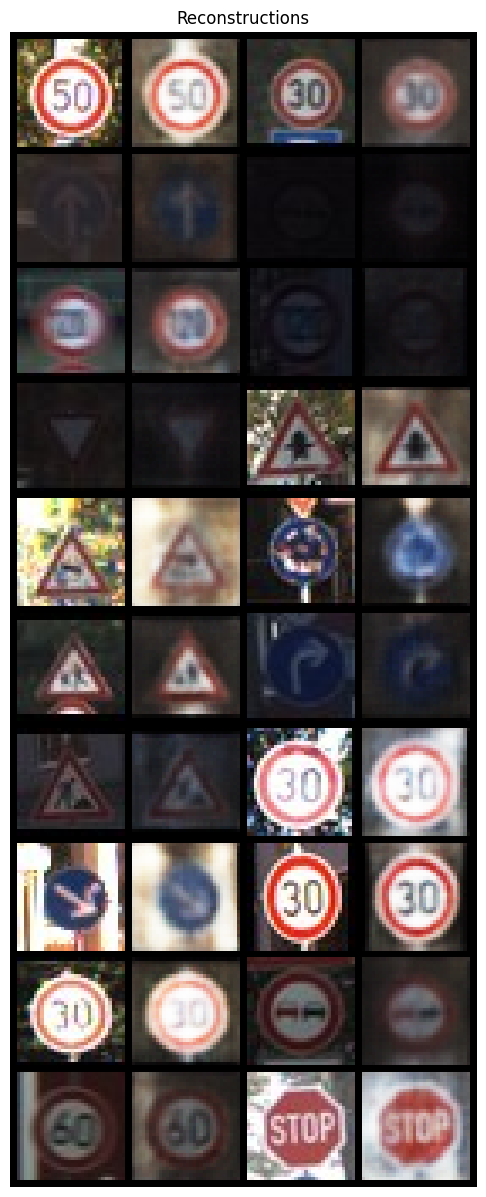

100%|██████████| 246/246 [00:27<00:00,  9.04it/s]


(Epoch 11/[train]) -> Total Loss:	5102.891 -> Reconstruction Loss:	3583.405 -> lr: 0.0009043820750088043


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 11/[val]) -> Total Loss:	5070.710 -> Reconstruction Loss:	3593.833 -> lr: 0.0009043820750088043


100%|██████████| 246/246 [00:27<00:00,  9.08it/s]


...

(Epoch 19/[val]) -> Total Loss:	4746.836 -> Reconstruction Loss:	3240.621 -> lr: 0.0008345137614500873


100%|██████████| 246/246 [00:27<00:00,  9.09it/s]


(Epoch 20/[train]) -> Total Loss:	4696.951 -> Reconstruction Loss:	3179.965 -> lr: 0.0008261686238355864


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]

(Epoch 20/[val]) -> Total Loss:	4732.624 -> Reconstruction Loss:	3227.349 -> lr: 0.0008261686238355864


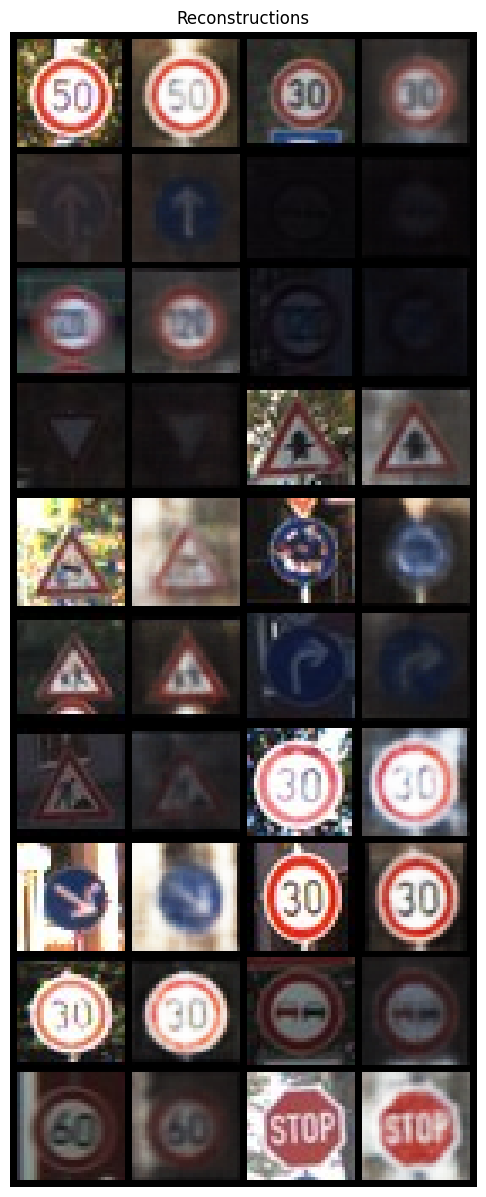

100%|██████████| 246/246 [00:27<00:00,  9.03it/s]


(Epoch 21/[train]) -> Total Loss:	4654.316 -> Reconstruction Loss:	3133.897 -> lr: 0.0008179069375972306


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 21/[val]) -> Total Loss:	4731.932 -> Reconstruction Loss:	3181.113 -> lr: 0.0008179069375972306


100%|██████████| 246/246 [00:27<00:00,  9.07it/s]


...

(Epoch 29/[val]) -> Total Loss:	4595.922 -> Reconstruction Loss:	3130.376 -> lr: 0.0007547192872036325


100%|██████████| 246/246 [00:27<00:00,  9.09it/s]


(Epoch 30/[train]) -> Total Loss:	4453.377 -> Reconstruction Loss:	2947.711 -> lr: 0.0007471720943315961


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]

(Epoch 30/[val]) -> Total Loss:	4582.465 -> Reconstruction Loss:	3104.304 -> lr: 0.0007471720943315961


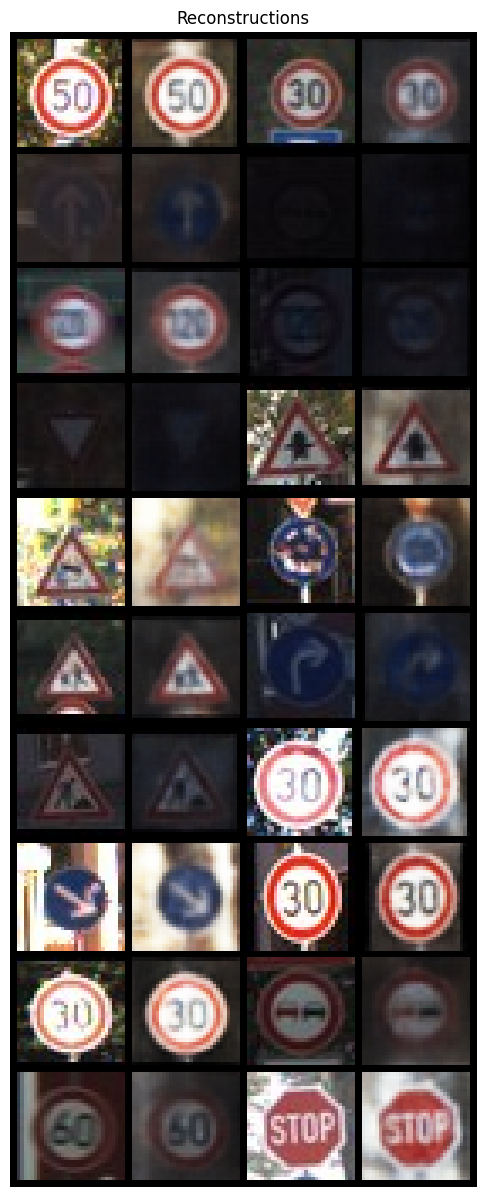

100%|██████████| 246/246 [00:27<00:00,  9.03it/s]


(Epoch 31/[train]) -> Total Loss:	4440.942 -> Reconstruction Loss:	2936.961 -> lr: 0.0007397003733882801


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 31/[val]) -> Total Loss:	4571.157 -> Reconstruction Loss:	3080.863 -> lr: 0.0007397003733882801


100%|██████████| 246/246 [00:27<00:00,  9.10it/s]


...

(Epoch 39/[val]) -> Total Loss:	4452.417 -> Reconstruction Loss:	2956.324 -> lr: 0.0006825545950103868


100%|██████████| 246/246 [00:27<00:00,  9.10it/s]


(Epoch 40/[train]) -> Total Loss:	4327.382 -> Reconstruction Loss:	2834.759 -> lr: 0.000675729049060283


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 40/[val]) -> Total Loss:	4460.859 -> Reconstruction Loss:	2989.187 -> lr: 0.000675729049060283


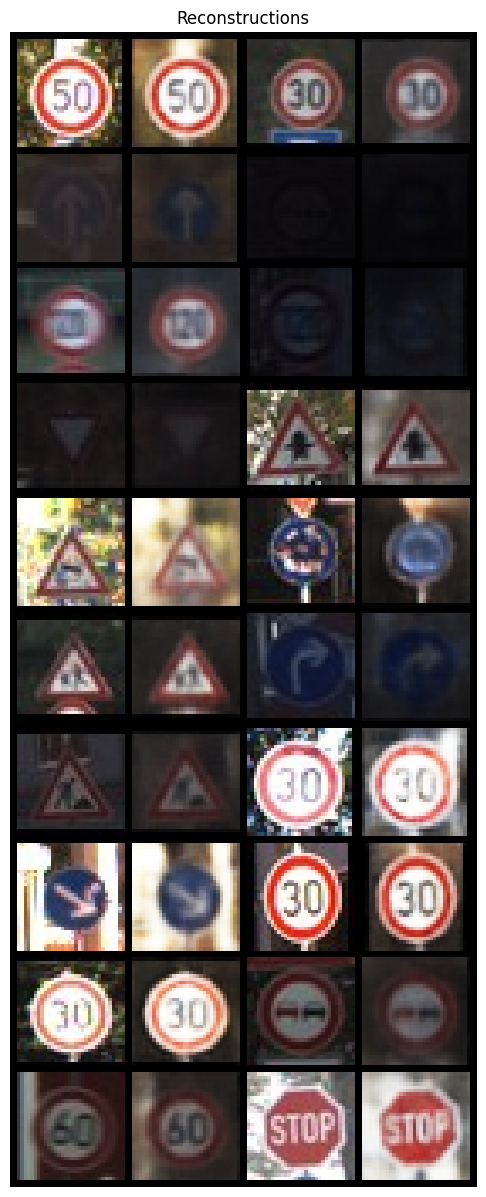

100%|██████████| 246/246 [00:27<00:00,  9.03it/s]


(Epoch 41/[train]) -> Total Loss:	4315.758 -> Reconstruction Loss:	2826.821 -> lr: 0.0006689717585696801


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 41/[val]) -> Total Loss:	4417.791 -> Reconstruction Loss:	2962.890 -> lr: 0.0006689717585696801


100%|██████████| 246/246 [00:27<00:00,  9.10it/s]


...

(Epoch 49/[val]) -> Total Loss:	4368.832 -> Reconstruction Loss:	2913.216 -> lr: 0.0006172901409422877


100%|██████████| 246/246 [00:27<00:00,  9.08it/s]


(Epoch 50/[train]) -> Total Loss:	4224.433 -> Reconstruction Loss:	2749.066 -> lr: 0.0006111172395328649


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 50/[val]) -> Total Loss:	4356.936 -> Reconstruction Loss:	2869.711 -> lr: 0.0006111172395328649


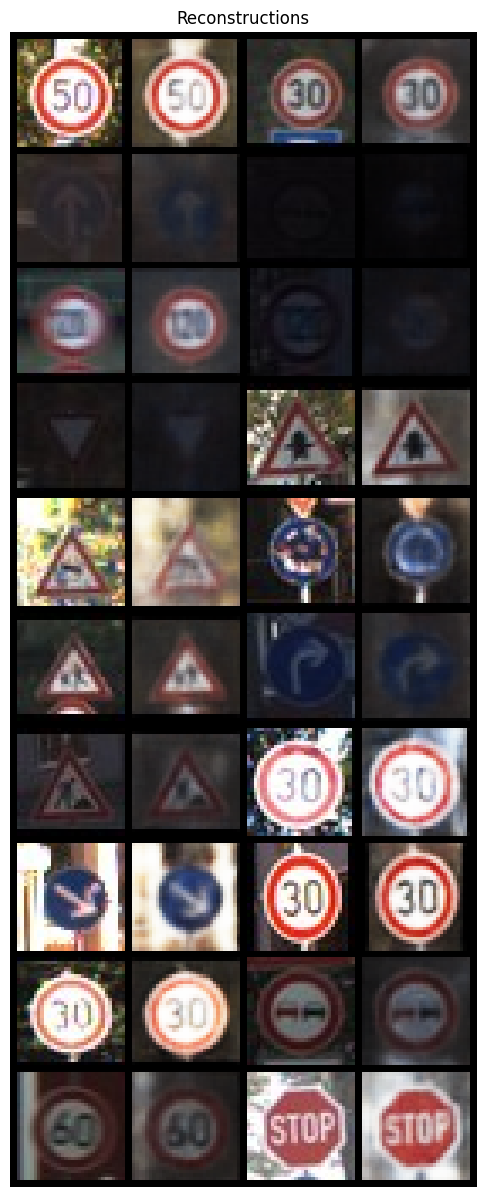

100%|██████████| 246/246 [00:28<00:00,  8.62it/s]


(Epoch 51/[train]) -> Total Loss:	4231.209 -> Reconstruction Loss:	2753.955 -> lr: 0.0006050060671375363


100%|██████████| 31/31 [00:24<00:00,  1.26it/s]


(Epoch 51/[val]) -> Total Loss:	4371.365 -> Reconstruction Loss:	2871.486 -> lr: 0.0006050060671375363


100%|██████████| 246/246 [00:27<00:00,  9.05it/s]


...

(Epoch 59/[val]) -> Total Loss:	4304.589 -> Reconstruction Loss:	2876.265 -> lr: 0.0005582661385478637


100%|██████████| 246/246 [00:30<00:00,  8.10it/s]


(Epoch 60/[train]) -> Total Loss:	4153.435 -> Reconstruction Loss:	2691.872 -> lr: 0.000552683477162385


100%|██████████| 31/31 [00:25<00:00,  1.19it/s]


(Epoch 60/[val]) -> Total Loss:	4348.544 -> Reconstruction Loss:	2948.760 -> lr: 0.000552683477162385


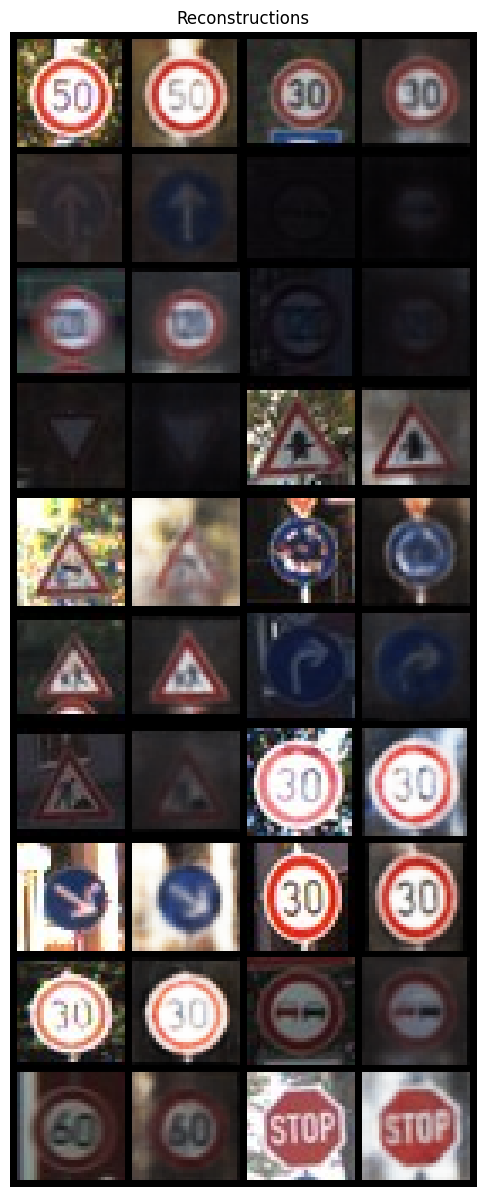

100%|██████████| 246/246 [00:30<00:00,  8.02it/s]


(Epoch 61/[train]) -> Total Loss:	4149.283 -> Reconstruction Loss:	2686.738 -> lr: 0.0005471566423907612


100%|██████████| 31/31 [00:25<00:00,  1.20it/s]


(Epoch 61/[val]) -> Total Loss:	4319.870 -> Reconstruction Loss:	2878.991 -> lr: 0.0005471566423907612


100%|██████████| 246/246 [00:30<00:00,  8.20it/s]


...

(Epoch 69/[val]) -> Total Loss:	4334.576 -> Reconstruction Loss:	2929.017 -> lr: 0.0005048858887870696


100%|██████████| 246/246 [00:30<00:00,  8.19it/s]


(Epoch 70/[train]) -> Total Loss:	4102.930 -> Reconstruction Loss:	2645.117 -> lr: 0.0004998370298991989


100%|██████████| 31/31 [00:25<00:00,  1.21it/s]

(Epoch 70/[val]) -> Total Loss:	4254.343 -> Reconstruction Loss:	2800.329 -> lr: 0.0004998370298991989


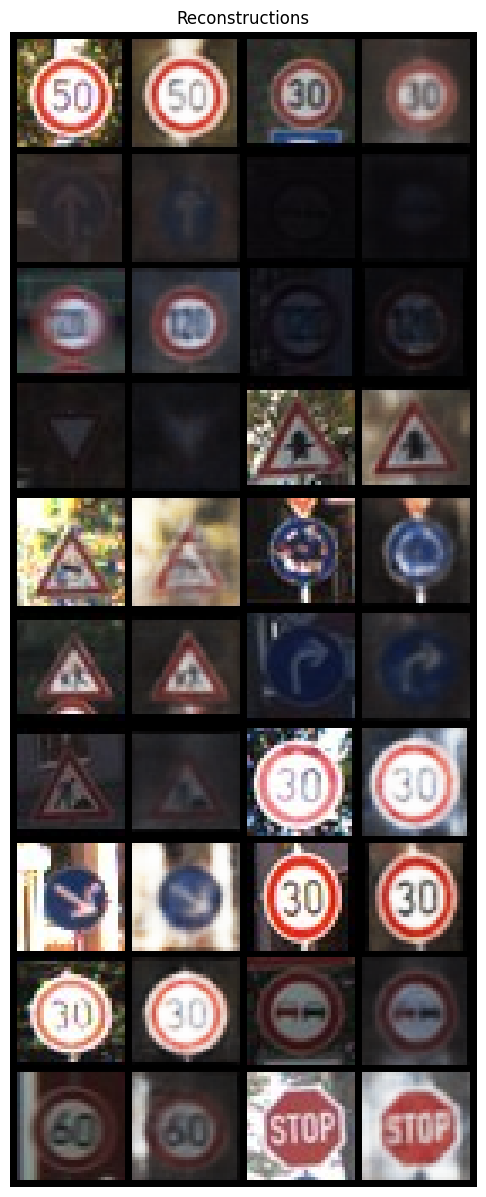

100%|██████████| 246/246 [00:30<00:00,  8.18it/s]


(Epoch 71/[train]) -> Total Loss:	4098.978 -> Reconstruction Loss:	2646.503 -> lr: 0.000494838659600207


100%|██████████| 31/31 [00:25<00:00,  1.20it/s]


(Epoch 71/[val]) -> Total Loss:	4280.217 -> Reconstruction Loss:	2826.548 -> lr: 0.000494838659600207


100%|██████████| 246/246 [00:29<00:00,  8.21it/s]


...

(Epoch 79/[val]) -> Total Loss:	4250.324 -> Reconstruction Loss:	2794.827 -> lr: 0.0004566097477439145


100%|██████████| 246/246 [00:30<00:00,  8.19it/s]


(Epoch 80/[train]) -> Total Loss:	4061.302 -> Reconstruction Loss:	2615.058 -> lr: 0.00045204365026647533


100%|██████████| 31/31 [00:25<00:00,  1.21it/s]

(Epoch 80/[val]) -> Total Loss:	4247.527 -> Reconstruction Loss:	2798.933 -> lr: 0.00045204365026647533


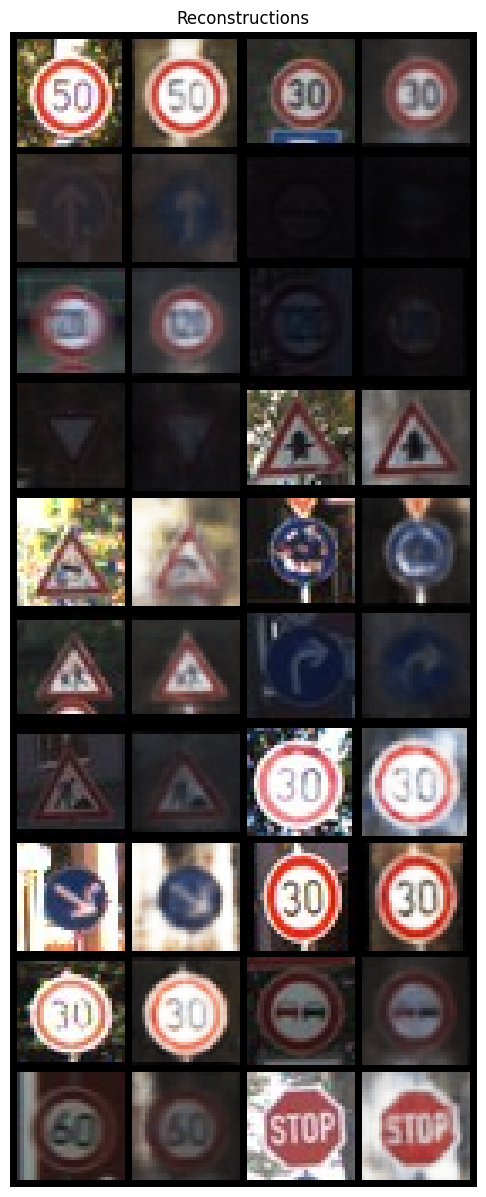

100%|██████████| 246/246 [00:30<00:00,  8.13it/s]


(Epoch 81/[train]) -> Total Loss:	4054.977 -> Reconstruction Loss:	2608.161 -> lr: 0.0004475232137638106


100%|██████████| 31/31 [00:26<00:00,  1.18it/s]


(Epoch 81/[val]) -> Total Loss:	4220.391 -> Reconstruction Loss:	2784.789 -> lr: 0.0004475232137638106


100%|██████████| 246/246 [00:30<00:00,  8.20it/s]


...

(Epoch 89/[val]) -> Total Loss:	4236.935 -> Reconstruction Loss:	2814.095 -> lr: 0.0004129496711338881


100%|██████████| 246/246 [00:29<00:00,  8.33it/s]


(Epoch 90/[train]) -> Total Loss:	4018.695 -> Reconstruction Loss:	2578.152 -> lr: 0.0004088201744225492


100%|██████████| 31/31 [00:26<00:00,  1.17it/s]

(Epoch 90/[val]) -> Total Loss:	4234.243 -> Reconstruction Loss:	2829.027 -> lr: 0.0004088201744225492


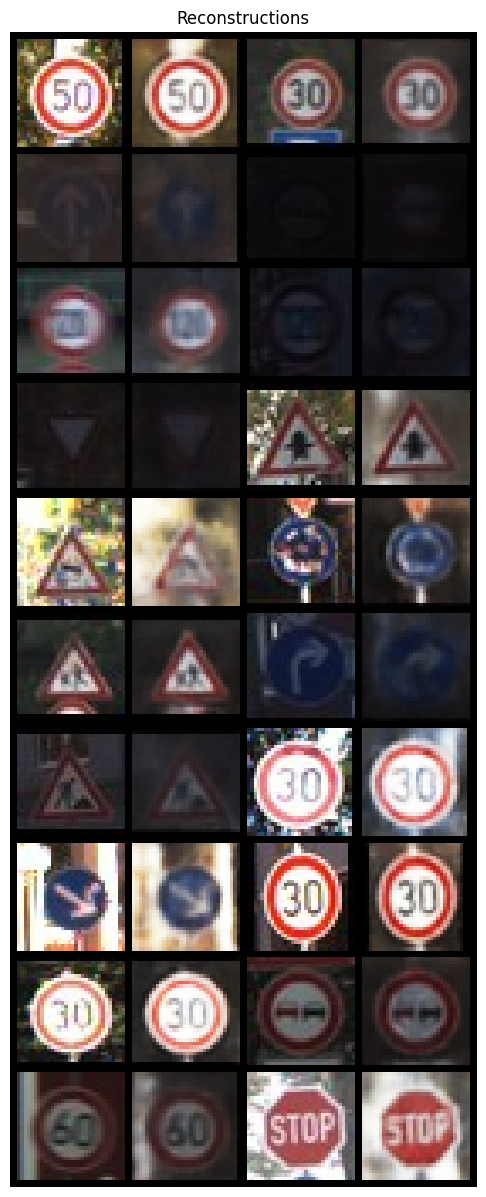

100%|██████████| 246/246 [00:30<00:00,  8.07it/s]


(Epoch 91/[train]) -> Total Loss:	4016.423 -> Reconstruction Loss:	2575.701 -> lr: 0.0004047319726783237


100%|██████████| 31/31 [00:25<00:00,  1.21it/s]

(Epoch 91/[val]) -> Total Loss:	4236.995 -> Reconstruction Loss:	2828.595 -> lr: 0.0004047319726783237
Early stopping


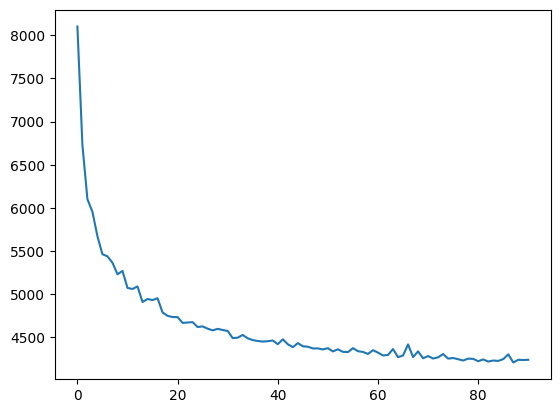

In [16]:
epochs = 100
warmup_epochs = 50
max_beta = 0.5
# max_beta = 1.0

early_stopping, val_lossses = train(model=vae, loaders=data_loaders, criterion=vae_loss_function, optimizer=optim, lr_scheduler=scheduler, 
                                early_stopping=early_stopping, num_epochs=epochs, warmup_epochs=warmup_epochs, loss_beta=max_beta)
early_stopping.load_best_model(vae)

plt.plot(val_lossses)

In [17]:
torch.save(vae.state_dict(), f="cvae.pth")

### VAE results

In [18]:
def visualize_reconstructions(model, input_imgs, labels, device):
    # Reconstruct images
    model.eval()
    with torch.no_grad():
        reconst_imgs, means, log_var = model(input_imgs.to(device), labels.to(device))
    reconst_imgs = reconst_imgs.cpu()
    
    # Plotting
    imgs = torch.stack([input_imgs, reconst_imgs], dim=1).flatten(0,1)
    grid = torchvision.utils.make_grid(imgs, nrow=6, normalize=False)
    grid = grid.permute(1, 2, 0)
    if len(input_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Reconstructions")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()


def generate_images(model, n_imgs, device):
    # Generate images
    model.eval()
    with torch.no_grad():
        generated_imgs = model.decoder(torch.randn([n_imgs, model.latent_dim]).to(device), torch.randint(0, model.num_classes, (n_imgs,)).to(device))
    generated_imgs = generated_imgs.cpu()
    
    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=False) # produces 'channels first' format
    grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
    if len(generated_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Generations")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()

In [19]:
vae.eval()
with torch.inference_mode():    
    test_losses = []
    for x, y in tqdm(data_loaders["test"]):
        x = x.to(device)
        y = y.to(device)
        x_hat, mean, logvar = vae(x, y)
        total_loss, _ = vae_loss_function(x, x_hat, mean, logvar)
        test_losses.append(total_loss.item())
    print(f"Mean test loss: {np.mean(np.array(test_losses))}")

100%|██████████| 31/31 [00:25<00:00,  1.20it/s]

Mean test loss: 4181.419071320564


torch.Size([27, 3, 32, 32])
torch.Size([27])


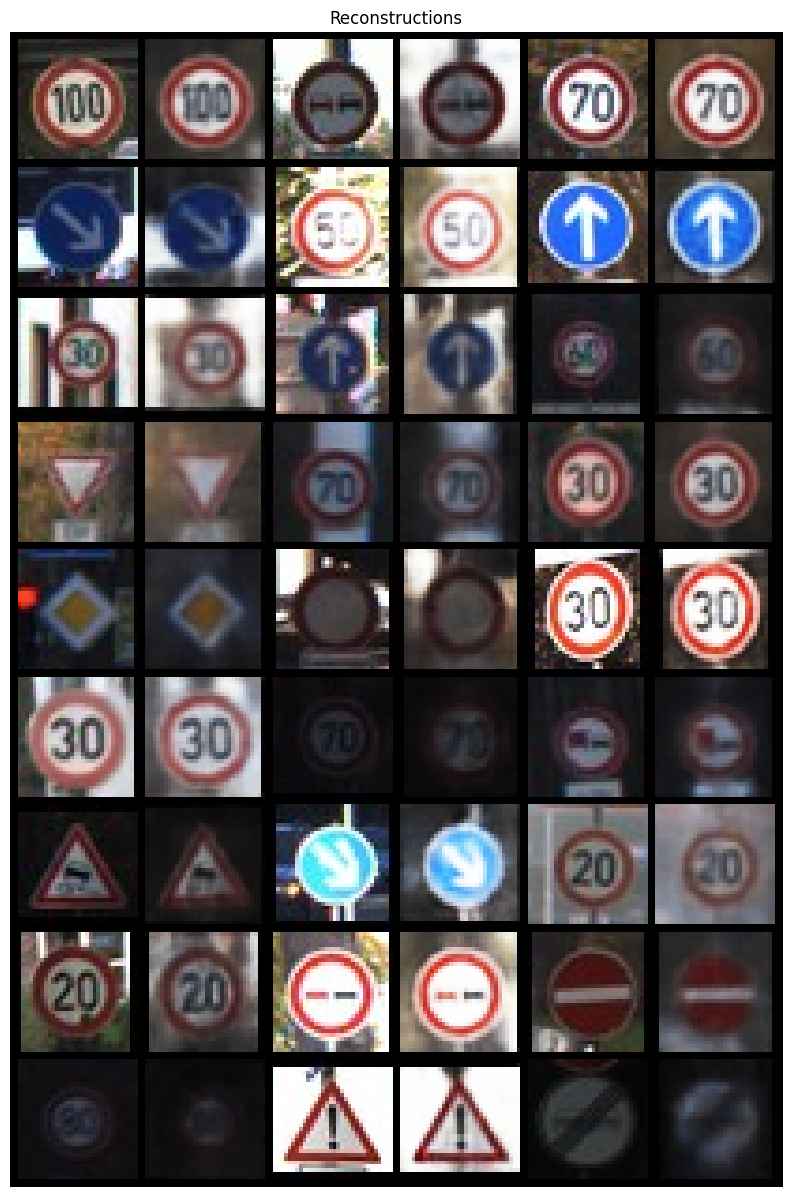

In [20]:
n_samples = 27
sample_imgs = torch.stack([data_loaders["test"].dataset[i][0] for i in range(n_samples)], dim=0)    # wraps all tensors in one one external tensor - [[..], [..], .., [..]]
sample_lables = torch.tensor([data_loaders["test"].dataset[i][1] for i in range(n_samples)])
print(sample_imgs.shape)
print(sample_lables.shape)
visualize_reconstructions(vae, input_imgs=sample_imgs, labels=sample_lables, device=device)

### FID Evaluation

In [21]:
vae = VAE(input_channels=input_channels, hidden_dim_channels=hidden_dim, latent_dim=latent_dim, num_classes=classes_num, class_embed_dim=y_embed_dim).to(device=device)
vae.load_state_dict(torch.load(f="cvae.pth"))

<All keys matched successfully>

In [22]:
test_data = [x for x, _ in data_loaders["test"]]
print(len(test_data), test_data[0].shape)
test_data = torch.cat(test_data)    # turns list of batches into one vector (without batch division)
test_data.shape

31 torch.Size([128, 3, 32, 32])


torch.Size([3920, 3, 32, 32])

In [23]:
latent_dim = 64
num_samples = 1000

vae.eval()
with torch.no_grad():
    fixed_noise = torch.randn(1000, latent_dim, device=device)
    rnd_labels = torch.randint(0, classes_num, size=(num_samples,), device=device)
    generations_vae = vae.decoder(fixed_noise, rnd_labels)
    

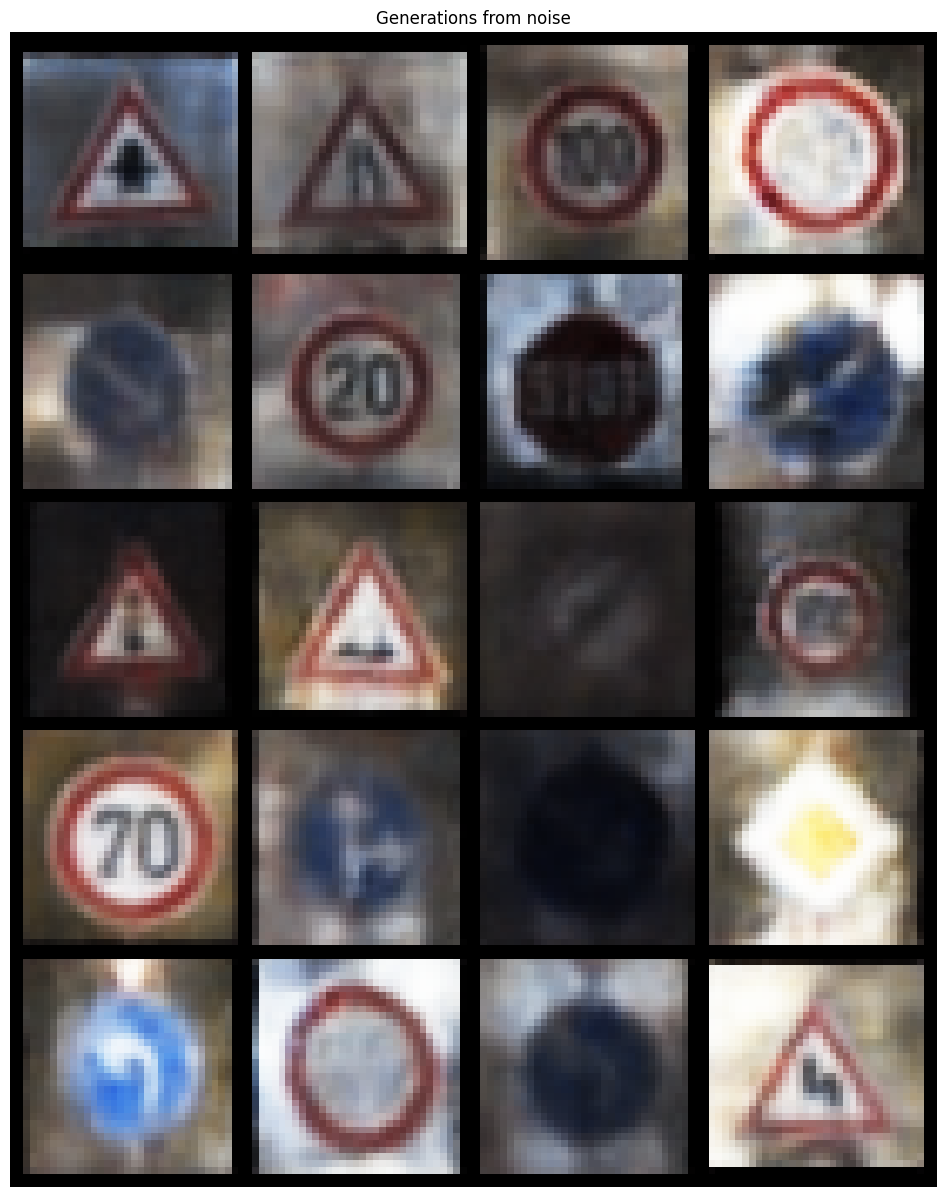

In [24]:
grid = torchvision.utils.make_grid(generations_vae.cpu()[:20], nrow=4, normalize=False) # produces 'channels first' format
grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
if len(generations_vae) == 4:
    plt.figure(figsize=(15,10))
else:
    plt.figure(figsize=(15,15))
plt.title("Generations from noise")
plt.imshow(grid)
plt.axis('off')
plt.show()

In [25]:
print(generations_vae.shape)
generations_vae_denorm = (generations_vae * 255).clamp(0, 255).to(torch.uint8)
torch.save(generations_vae_denorm.cpu().detach(),"poniedzialek_Bargieł_Kwaśniak.pt")

torch.Size([1000, 3, 32, 32])


In [26]:
import os
import torch
from torchvision.utils import save_image

# Create directories to store the images temporarily
os.makedirs('real_imgs', exist_ok=True)
os.makedirs('fake_imgs', exist_ok=True)

for i, (img, y) in enumerate(test_dataset):
    save_image(img, f'real_imgs/real_{i}_class_{y}.png')

# Save generated images
for i, img in enumerate(generations_vae.cpu()):
    save_image(img, f'fake_imgs/fake_{i}.png')
    
print("All images saved to disk!")

All images saved to disk!


In [27]:
!python -m pytorch_fid real_imgs fake_imgs

100%|███████████████████████████████████████████| 20/20 [02:22<00:00,  7.11s/it]
FID:  81.78705852075831


#### Evaluator

In [28]:
class Evaluator(nn.Module):
    def __init__(self, input_dim, hidden_dim, classes_num):
        super(Evaluator, self).__init__()

        self.fc_1 = nn.Linear(input_dim, hidden_dim)
        self.fc_2 = nn.Linear(hidden_dim, 100)
        self.fc_out  = nn.Linear(100, classes_num)
        
        self.LeakyReLU = nn.LeakyReLU(0.2)
        
    def get_features(self, x):
        x = torch.flatten(x, 1)
        x = self.LeakyReLU(self.fc_1(x))
        x = self.LeakyReLU(self.fc_2(x))
        return x
    

    def forward(self, x):
        x = self.get_features(x)
        x = self.fc_out(x)
        return x

evaluator = Evaluator(input_size * input_size * input_channels, 256, classes_num).to(device)

In [29]:
# Optimizers
optimizer = torch.optim.Adam(evaluator.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optimizer, gamma=0.97)

# loss
criterion = nn.CrossEntropyLoss()

In [ ]:
num_epochs = 50
for epoch in tqdm(range(num_epochs)):
    for data, targets in data_loaders["train"]:
        data = data.to(device)
        targets = targets.to(device)

        results = evaluator(data)
        loss = criterion(results, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

In [ ]:
num_correct = 0
total_guesses = 0

evaluator.eval()
with torch.no_grad():
    for data, targets in data_loaders["test"]:
        # Sends data and targets to device
        data = data.to(device)
        targets = targets.to(device)

        # Acquires the network's best guesses at each class
        results = evaluator(data)
        best_guesses = torch.argmax(results, 1)

        # Updates number of correct and total guesses
        num_correct += torch.eq(targets, best_guesses).sum().item()
        total_guesses += len(targets)

print("Correctly guessed ", num_correct/total_guesses*100, "% of the dataset")

Correctly guessed  94.13265306122449 % of the dataset


In [ ]:
test_data = [x for x, _ in data_loaders["test"]]
print(len(test_data), test_data[0].shape)
test_data = torch.cat(test_data)    # turns list of batches into one vector (without batch division)
test_data.shape

31 torch.Size([128, 3, 32, 32])


torch.Size([3920, 3, 32, 32])

In [ ]:
latent_dim = 64
num_samples = 1000

with torch.no_grad():
    fixed_noise = torch.randn(num_samples, latent_dim, device=device)
    rnd_labels = torch.randint(0, classes_num, size=(num_samples,), device=device)
    generations_vae = vae.decoder(fixed_noise, rnd_labels)
    dist_generations_vae = evaluator.get_features(generations_vae.to(device)).cpu()
    dist_test_data = evaluator.get_features(test_data.to(device)).cpu()

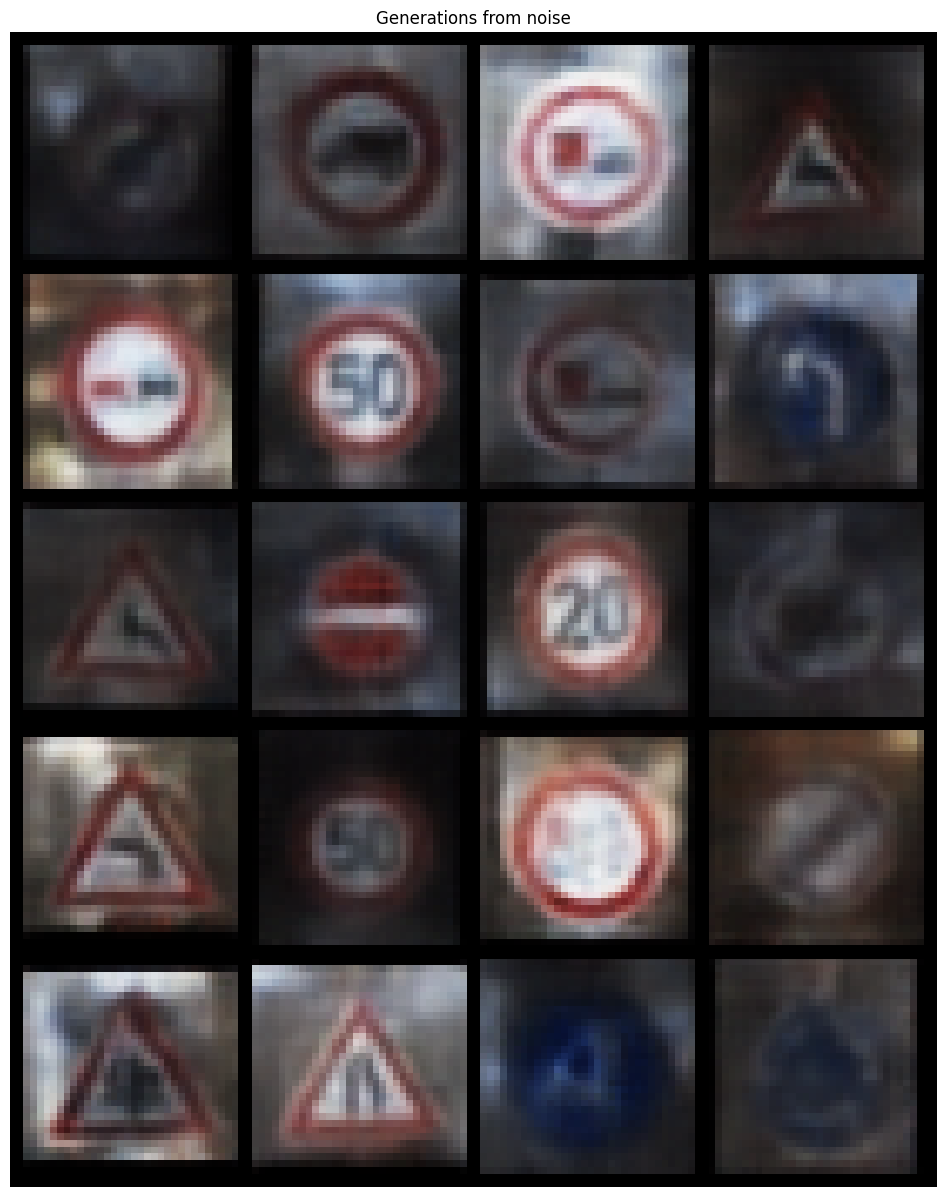

In [ ]:
grid = torchvision.utils.make_grid(generations_vae.cpu()[:20], nrow=4, normalize=False) # produces 'channels first' format
grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
if len(generations_vae) == 4:
    plt.figure(figsize=(15,10))
else:
    plt.figure(figsize=(15,15))
plt.title("Generations from noise")
plt.imshow(grid)
plt.axis('off')
plt.show()

In [ ]:
print(generations_vae.shape)
generations_vae = (generations_vae * 255).clamp(0, 255).to(torch.uint8)
torch.save(generations_vae.cpu().detach(),"poniedzialek_Bargieł_Kwaśniak.pt")

torch.Size([1000, 3, 32, 32])


#### FID impl

In [ ]:
######### Frechet Inception distance based on implementation from https://github.com/mseitzer/pytorch-fid

import numpy as np
from scipy import linalg


def calculate_frechet_distance(distribution_1, distribution_2, eps=1e-6):
    mu1 = np.mean(distribution_1, axis=0)
    sigma1 = np.cov(distribution_1, rowvar=False)

    mu2 = np.mean(distribution_2, axis=0)
    sigma2 = np.cov(distribution_2, rowvar=False)

    """Numpy implementation of the Frechet Distance.
    The Frechet distance between two multivariate Gaussians X_1 ~ N(mu_1, C_1)
    and X_2 ~ N(mu_2, C_2) is
            d^2 = ||mu_1 - mu_2||^2 + Tr(C_1 + C_2 - 2*sqrt(C_1*C_2)).
    Stable version by Dougal J. Sutherland.
    Params:
    -- mu1   : Numpy array containing the activations of a layer of the
               inception net (like returned by the function 'get_predictions')
               for generated samples.
    -- mu2   : The sample mean over activations, precalculated on an
               representative data set.
    -- sigma1: The covariance matrix over activations for generated samples.
    -- sigma2: The covariance matrix over activations, precalculated on an
               representative data set.
    Returns:
    --   : The Frechet Distance.
    """

    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)

    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)

    assert mu1.shape == mu2.shape, \
        'Training and test mean vectors have different lengths'
    assert sigma1.shape == sigma2.shape, \
        'Training and test covariances have different dimensions'

    diff = mu1 - mu2

    # Product might be almost singular
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if not np.isfinite(covmean).all():
        msg = ('fid calculation produces singular product; '
               'adding %s to diagonal of cov estimates') % eps
        print(msg)
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))

    # Numerical error might give slight imaginary component
    if np.iscomplexobj(covmean):
        if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
            m = np.max(np.abs(covmean.imag))
            raise ValueError('Imaginary component {}'.format(m))
        covmean = covmean.real

    tr_covmean = np.trace(covmean)

    return (diff.dot(diff) + np.trace(sigma1) +
            np.trace(sigma2) - 2 * tr_covmean)

In [ ]:
print(f"FD vae_generations: {calculate_frechet_distance(dist_test_data.numpy(), dist_generations_vae.numpy())}")

FD vae_generations: 447.064813147932


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_89395/2261845342.py:46: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


- FID from torchmetrics could be used for most reliable / independent tests 